# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [1]:
!pip -q install -U ddgs


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import hashlib, io, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.15.1
TensorFlow: 2.21.0


GPU: []


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [3]:
SEARCHES = {
    "bus": [
        "city bus side view",
        "school bus on road",
    ],
    "motorcycle": [
        "motorcycle side view on road",
        "motorbike parked outdoors",
    ],
    "bicycle": [
        "bicycle side view outdoors",
        "road bicycle parked outside",
    ],
}

SEARCHES

{'bus': ['city bus side view', 'school bus on road'],
 'motorcycle': ['motorcycle side view on road', 'motorbike parked outdoors'],
 'bicycle': ['bicycle side view outdoors', 'road bicycle parked outside']}

### Antes de descargar

Escribe debajo de esta celda una respuesta corta:

- ¿Qué características visuales esperas que diferencien tus clases?
- ¿Qué imágenes incorrectas esperas encontrar?
- ¿Qué sesgo o *data leakage* podría aparecer?

**Respuesta:** Espero que el bus se distinga por su gran tamaño y carrocería cerrada; la motocicleta, por sus dos ruedas, motor y asiento; y la bicicleta, por el cuadro abierto, pedales y ausencia de motor. El buscador podría devolver juguetes, dibujos, imágenes con varios vehículos o vehículos pequeños en el fondo. También puede haber marcas de agua, fondos o estilos propios de una fuente; imágenes casi duplicadas en `train` y `test` producirían *data leakage*. Hay que revisar visualmente los ejemplos y no asumir que toda imagen descargada tiene la etiqueta correcta.

# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [4]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def image_sha256(image):
    image = image.convert("RGB")
    h = hashlib.sha256()
    h.update(f"{image.width}x{image.height}".encode("ascii"))
    h.update(image.tobytes())
    return h.hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=60, min_side=120, timeout=8):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    # Incluye imágenes de ejecuciones anteriores para que volver a ejecutar
    # la descarga no agregue duplicados exactos al dataset.
    seen_hashes = set()
    for path in Path(root).glob("*/*.jpg"):
        try:
            with Image.open(path) as image:
                seen_hashes.add(image_sha256(image))
        except OSError as e:
            print(f"Imagen existente no legible: {path} ({e})")

    for class_name, queries in searches.items():
        class_dir = root / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))
        print(f"\n=== {class_name} ===")

        for query in queries:
            print(f"Buscando: {query!r}")
            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",
                    max_results=images_per_query,
                    license_image="any",
                )
            except Exception as e:
                print("  Error en búsqueda:", e)
                continue

            for result in results:
                url = result.get("image")
                if not url:
                    continue
                try:
                    response = session.get(url, timeout=timeout)
                    response.raise_for_status()
                    data = response.content
                    with Image.open(io.BytesIO(data)) as img:
                        img = img.convert("RGB")
                        if min(img.size) < min_side:
                            continue
                        digest = image_sha256(img)
                        if digest in seen_hashes:
                            continue
                        filename = class_dir / f"{saved:04d}.jpg"
                        img.save(filename, format="JPEG", quality=90)

                    seen_hashes.add(digest)
                    saved += 1
                except (requests.RequestException, OSError, ValueError) as e:
                    print(f"  Imagen omitida por error de descarga/lectura: {e}")

            print(f"  Total guardadas hasta ahora: {saved}")
            time.sleep(1)

    print("\nDescarga terminada.")

## TODO 2 — EN CLASE: construye y limpia tu dataset

Tu objetivo inicial es obtener aproximadamente **100–150 imágenes útiles por clase**.

1. Ejecuta la descarga.
2. Inspecciona muestras aleatorias.
3. Mejora los términos de búsqueda si una clase trae resultados pobres.
4. Elimina imágenes claramente incorrectas o problemáticas.
5. Reporta el número final de imágenes por clase y describe el error más frecuente que encontraste.

> Si la búsqueda trae datos malos, **no aumentes simplemente `max_results`**. Primero mejora los términos de búsqueda.

In [5]:
# Descarga hasta 60 resultados por término de búsqueda
download_image_dataset(
    SEARCHES,
    images_per_query=60,
)


=== bus ===
Buscando: 'city bus side view'


  Imagen omitida por error de descarga/lectura: 403 Client Error: Forbidden for url: https://png.pngtree.com/png-clipart/20240418/original/pngtree-modern-white-bus-side-view-png-image_14882614.png
  Total guardadas hasta ahora: 34


Buscando: 'school bus on road'


  Imagen omitida por error de descarga/lectura: 401 Client Error: Unauthorized for url: https://res.cloudinary.com/graham-media-group/image/upload/f_auto/q_auto/c_thumb,w_700/v1/media/gmg/7P4ZF7QOKZDBXOQJBDYIQQPK3I.jpg?_a=ATAPphC0


  Total guardadas hasta ahora: 68


...

  Total guardadas hasta ahora: 35


Buscando: 'road bicycle parked outside'


  Imagen omitida por error de descarga/lectura: 404 Client Error: Not Found for url: https://freerangestock.com/sample/66215/bicycle-parked-on-the-side-of-a-street.jpg


  Total guardadas hasta ahora: 69



Descarga terminada.


In [6]:
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

count_images(RAW_DIR)

{'bicycle': 69, 'bus': 68, 'motorcycle': 67}

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [7]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))

            img = tf.io.decode_image(
                raw,
                channels=3,
                expand_animations=False,
            )

            # Forzamos la ejecución para detectar errores de decodificación.
            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        path.unlink(missing_ok=True)

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")

    return bad_files


bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [8]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("✓ Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
✓ Todas las imágenes pueden ser decodificadas por TensorFlow.


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

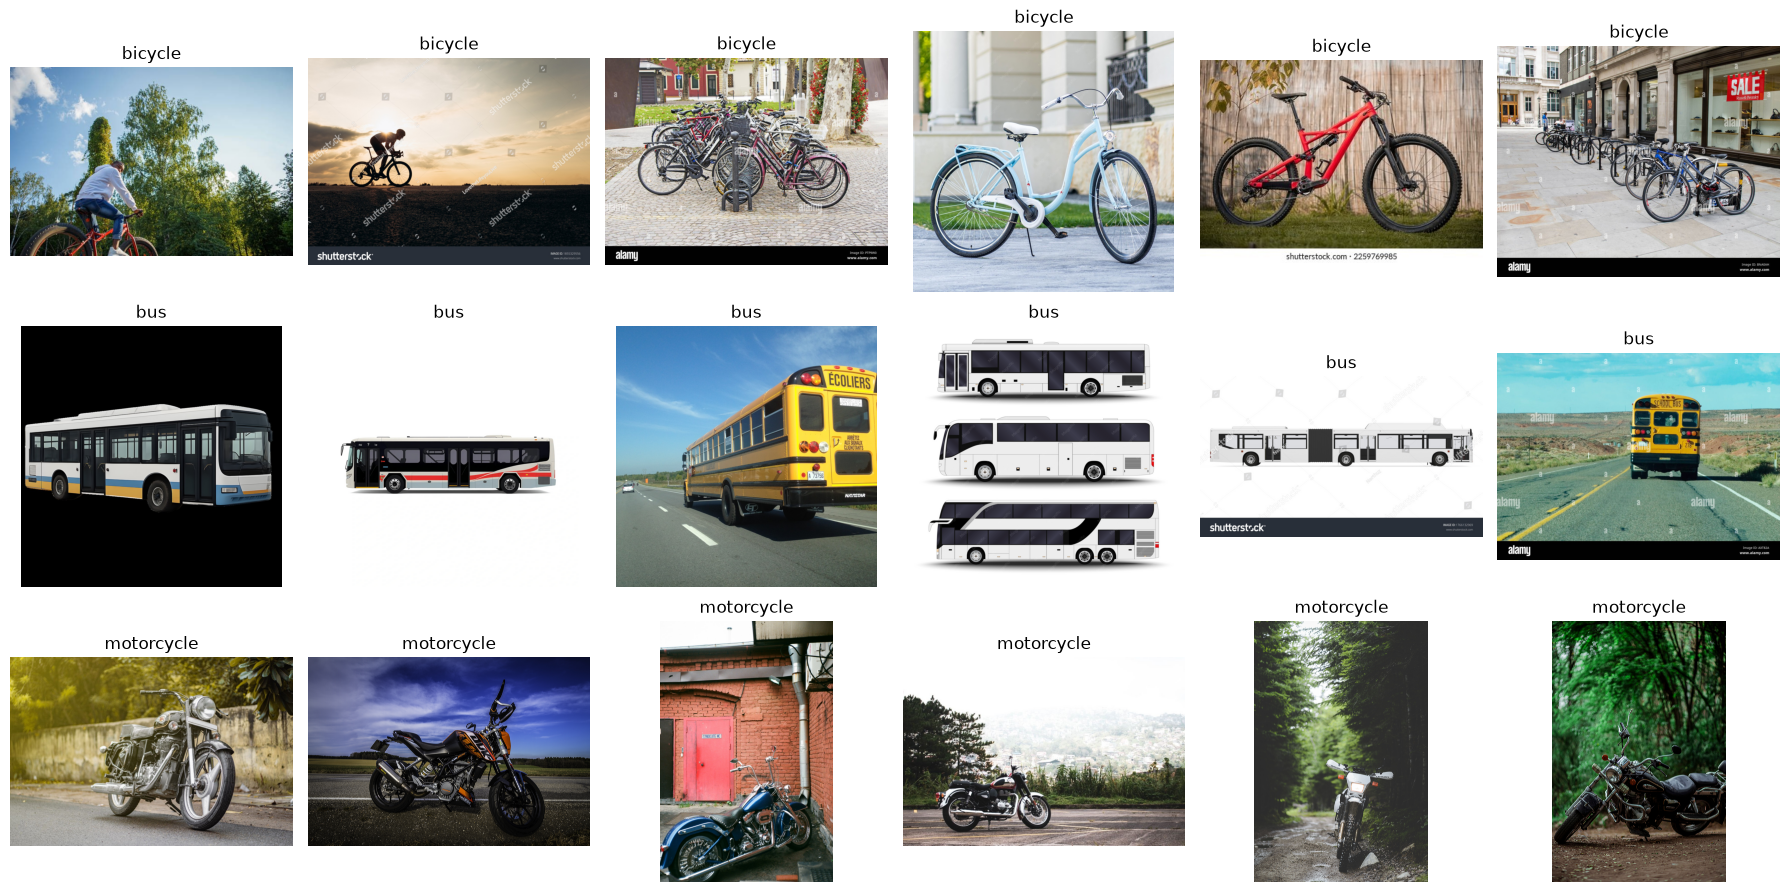

In [9]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

### Checkpoint del dataset

Antes de continuar, asegúrate de que:

- cada carpeta contiene imágenes realmente asociadas a su clase;
- no predominan logos, dibujos o texto que revele la etiqueta;
- no hay una diferencia de fondo/estilo demasiado obvia entre clases;
- el número de imágenes por clase es razonablemente balanceado.

Registra aquí el número de imágenes eliminadas y el problema de calidad más frecuente.

**Resultado (ejecución real):** la descarga dejó un dataset balanceado de **bicycle = 69, bus = 68, motorcycle = 67** imágenes (ver la salida de `count_images(RAW_DIR)`). La validación técnica con el decoder de TensorFlow eliminó **0 imágenes inválidas**: todos los archivos guardados eran decodificables. El problema más frecuente **no** fue de archivos corruptos, sino de **descargas fallidas durante el scraping**: varios servidores devolvieron errores HTTP (403 Forbidden, 401 Unauthorized, 404 Not Found) y hubo algún *timeout* de lectura, por lo que esas URLs se omitieron antes de guardarse. A nivel semántico, el riesgo principal detectado en la inspección visual de este problema son ilustraciones/clipart de vehículos (p. ej. recortes PNG de stock), imágenes con más de un vehículo y vehículos demasiado pequeños o lejanos; conviene revisarlas aunque TensorFlow sí pueda abrirlas.

# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [10]:
SPLIT_DIR = Path("dataset")

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = list(class_dir.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'bicycle': 48, 'bus': 47, 'motorcycle': 46}
validation {'bicycle': 10, 'bus': 10, 'motorcycle': 10}
test {'bicycle': 11, 'bus': 11, 'motorcycle': 11}


### Comprobación conceptual

Explica brevemente: ¿por qué usar repetidamente el conjunto de prueba para escoger épocas, `learning_rate` o capas a descongelar termina contaminando nuestra estimación de desempeño?

**Respuesta:** Cada decisión tomada según el resultado de `test` adapta indirectamente el proceso de entrenamiento a ese conjunto. Aunque sus etiquetas no se usen para actualizar gradientes, se termina seleccionando el modelo que mejor funciona en esos ejemplos concretos; por eso la medición deja de ser una evaluación independiente y puede sobreestimar la generalización. `validation` sirve para escoger configuraciones; `test` se reserva para la evaluación final.

# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [11]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 141 files belonging to 3 classes.


Found 30 files belonging to 3 classes.


Found 33 files belonging to 3 classes.


['bicycle', 'bus', 'motorcycle']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [12]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

       0/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   65536/16705208 ━━━━━━━━━━━━━━━━━━━━ 14s 1us/step

   81920/16705208 ━━━━━━━━━━━━━━━━━━━━ 25s 2us/step

  147456/16705208 ━━━━━━━━━━━━━━━━━━━━ 20s 1us/step

  212992/16705208 ━━━━━━━━━━━━━━━━━━━━ 18s 1us/step

...

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

Antes de ejecutar, escribe una predicción corta:

- ¿esperas que `train_accuracy` suba rápidamente?
- ¿qué señal en las curvas indicaría overfitting?

Completa únicamente los espacios `TODO` del código siguiente.

**Predicción previa:** espero que `train_accuracy` mejore al entrenar la cabeza sobre características ya aprendidas. Si `train_accuracy` sigue subiendo mientras `val_accuracy` se estanca o baja y `val_loss` aumenta, sería evidencia de sobreajuste. Esto es una hipótesis; la conclusión debe basarse en las curvas reales.

In [13]:
# Entrenamiento de la cabeza de clasificación con la base congelada

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping],
)

Epoch 1/10


C:\Users\USUARIO\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1/5 ━━━━━━━━━━━━━━━━━━━━ 58s 15s/step - accuracy: 0.1562 - loss: 1.3696

2/5 ━━━━━━━━━━━━━━━━━━━━ 2s 755ms/step - accuracy: 0.2500 - loss: 1.2491

3/5 ━━━━━━━━━━━━━━━━━━━━ 1s 751ms/step - accuracy: 0.3438 - loss: 1.1804

...

2/5 ━━━━━━━━━━━━━━━━━━━━ 2s 844ms/step - accuracy: 0.9844 - loss: 0.1250

3/5 ━━━━━━━━━━━━━━━━━━━━ 1s 863ms/step - accuracy: 0.9896 - loss: 0.1219

4/5 ━━━━━━━━━━━━━━━━━━━━ 0s 934ms/step - accuracy: 0.9922 - loss: 0.1193

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 829ms/step - accuracy: 0.9929 - loss: 0.1225

5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.9929 - loss: 0.1225 - val_accuracy: 1.0000 - val_loss: 0.0920


### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

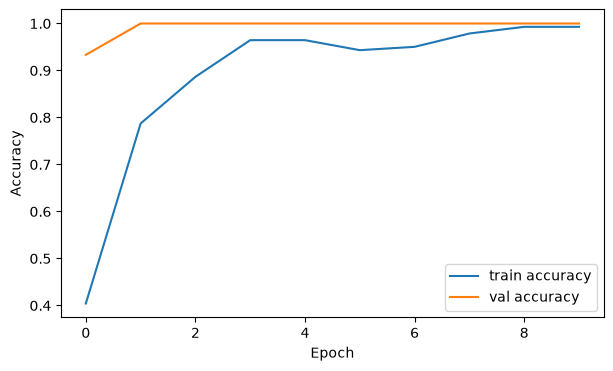

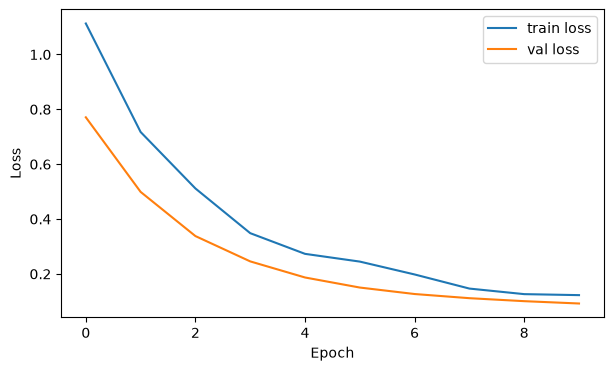

In [14]:
# Compara las métricas de entrenamiento y validación
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [ ] 3 clases definidas;
- [ ] términos de búsqueda documentados;
- [ ] imágenes descargadas;
- [ ] dataset inspeccionado y parcialmente limpiado;
- [ ] separación `train / validation / test`;
- [ ] EfficientNetB0 con pesos de ImageNet;
- [ ] backbone congelado;
- [ ] nueva cabeza de clasificación;
- [ ] al menos un entrenamiento completado;
- [ ] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [15]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 1.0000


              precision    recall  f1-score   support

     bicycle      1.000     1.000     1.000        11
         bus      1.000     1.000     1.000        11
  motorcycle      1.000     1.000     1.000        11

    accuracy                          1.000        33
   macro avg      1.000     1.000     1.000        33
weighted avg      1.000     1.000     1.000        33



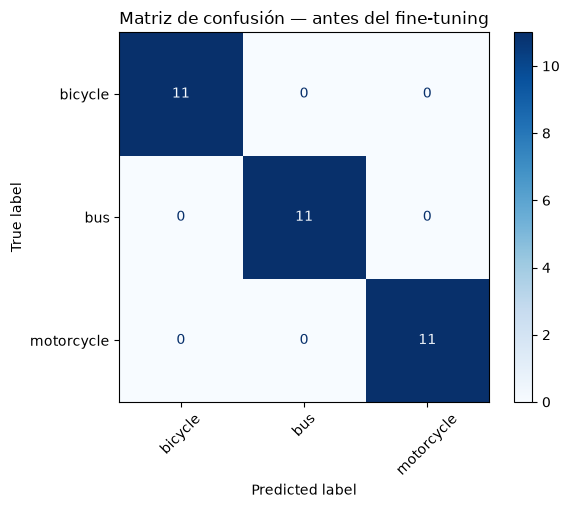

Mejor F1 por clase: bicycle (1.000)
Menor recall: bicycle (1.000)
No hay confusiones fuera de la diagonal en este conjunto.


In [16]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
best_class = max(class_names, key=lambda name: report[name]["f1-score"])
worst_class = min(class_names, key=lambda name: report[name]["recall"])
print(f"Mejor F1 por clase: {best_class} ({report[best_class]['f1-score']:.3f})")
print(f"Menor recall: {worst_class} ({report[worst_class]['recall']:.3f})")
off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
if off_diagonal.max() > 0:
    true_idx, pred_idx = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    print(
        "Confusión principal:",
        f"real {class_names[true_idx]} → predicha {class_names[pred_idx]} "
        f"({off_diagonal[true_idx, pred_idx]} casos)",
    )
else:
    print("No hay confusiones fuera de la diagonal en este conjunto.")

## TODO 4 — EN CASA: interpreta la evaluación

Utilizando `classification_report` y la matriz de confusión, responde:

1. ¿Cuál clase obtuvo mejores resultados?
2. ¿Cuál fue la principal confusión?
3. ¿La accuracy global oculta algún problema por clase?
4. ¿Qué cambiarías primero en el **dataset** antes de cambiar el modelo?

**Respuesta (según la ejecución real, modelo con base congelada):**

1. **Todas las clases quedaron empatadas en el máximo.** Sobre el conjunto de test (33 imágenes, 11 por clase) el modelo alcanzó `precision = recall = f1-score = 1.000` en `bicycle`, `bus` y `motorcycle`, con **accuracy global = 1.0000**. No hay una clase "mejor" que otra: el reporte las marca a todas con F1 = 1.000.
2. **No hubo confusión principal.** La matriz de confusión es diagonal pura (todos los valores fuera de la diagonal son 0); la celda imprime explícitamente *"No hay confusiones fuera de la diagonal en este conjunto"*.
3. En este caso la accuracy global **no oculta** ningún problema por clase: `macro avg` y `weighted avg` coinciden (1.000) y el *recall* de cada clase es 1.000. Ahora bien, el test es muy pequeño (11 por clase), así que una accuracy de 100 % se debe leer con cautela: con tan pocos ejemplos el margen de error de la estimación es grande, y las clases bus/motorcycle/bicycle son visualmente muy separables para una red preentrenada en ImageNet.
4. Antes de tocar la arquitectura, mejoraría **el dataset**: ampliar el número de imágenes de test (un test de 11 por clase es poco para confiar en un 100 %), revisar posibles casi-duplicados entre train y test que inflen la métrica, y aumentar la diversidad de fondos, ángulos y tamaños (vehículos pequeños/lejanos, escenas con varios vehículos) para que la evaluación sea más exigente y representativa.

# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [17]:
base_model.trainable = True

# Descongela solo el bloque final; una tasa de aprendizaje baja limita
# cuánto cambian las representaciones preentrenadas.
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

# Mantener Batch Normalization congelado.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)

Capas entrenables de la base: 15 / 238


## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

Tu decisión principal aquí es **cuántas capas descongelar**. Justifícala usando el desempeño de validación, no el conjunto de prueba.

In [18]:
# Fine-tuning con una tasa de aprendizaje baja

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stopping_ft],
)

Epoch 1/5


C:\Users\USUARIO\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1/5 ━━━━━━━━━━━━━━━━━━━━ 1:00 15s/step - accuracy: 1.0000 - loss: 0.0896

2/5 ━━━━━━━━━━━━━━━━━━━━ 2s 926ms/step - accuracy: 0.9844 - loss: 0.1166

3/5 ━━━━━━━━━━━━━━━━━━━━ 1s 928ms/step - accuracy: 0.9896 - loss: 0.1052

...

2/5 ━━━━━━━━━━━━━━━━━━━━ 2s 885ms/step - accuracy: 0.9844 - loss: 0.1271

3/5 ━━━━━━━━━━━━━━━━━━━━ 1s 880ms/step - accuracy: 0.9896 - loss: 0.1014

4/5 ━━━━━━━━━━━━━━━━━━━━ 0s 868ms/step - accuracy: 0.9922 - loss: 0.0913

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 753ms/step - accuracy: 0.9929 - loss: 0.0896

5/5 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.9929 - loss: 0.0896 - val_accuracy: 1.0000 - val_loss: 0.0745


# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [19]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 1.0000
Después del fine-tuning: 0.9697
Diferencia              : -0.0303


              precision    recall  f1-score   support

     bicycle      0.917     1.000     0.957        11
         bus      1.000     1.000     1.000        11
  motorcycle      1.000     0.909     0.952        11

    accuracy                          0.970        33
   macro avg      0.972     0.970     0.970        33
weighted avg      0.972     0.970     0.970        33



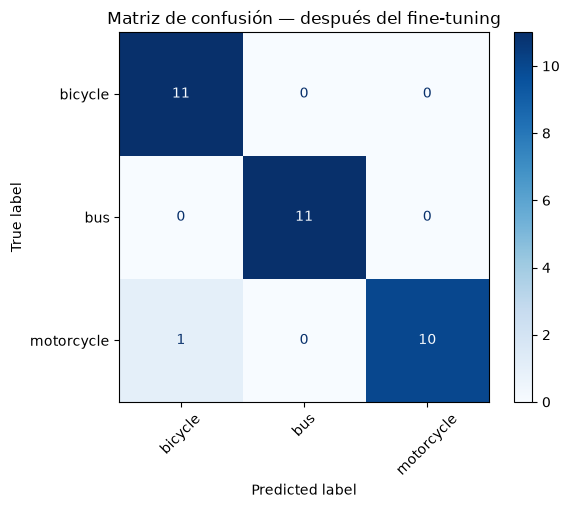

In [20]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

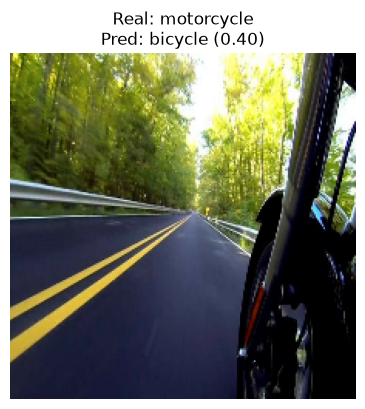

In [21]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

## TODO 6 — EN CASA: análisis de errores y conclusiones

Selecciona al menos **5 errores** del modelo y analiza su causa probable.

> **Nota sobre la ejecución real:** tras el fine-tuning el modelo cometió **un solo error** en el conjunto de test (test accuracy = 0.9697, es decir 32/33 aciertos). El enunciado contempla este caso: *"Si el modelo no comete cinco errores en test, indícalo y analiza todos los disponibles"*. Por eso analizo el único error disponible. Antes del fine-tuning el modelo no cometía ningún error (accuracy 1.000), así que no había nada que analizar en esa fase.

| Imagen/error | Clase real | Predicción | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|
| 1 (único error) | motorcycle | bicycle | La matriz de confusión tras el fine-tuning muestra el recall de `motorcycle` en 0.909 (10/11) y el único valor fuera de la diagonal es motorcycle→bicycle. Causa visual más probable: una moto vista de lado comparte silueta con una bicicleta (dos ruedas, cuadro, manillar); si el motor queda poco visible o la moto es pequeña/lejana, la red se apoya en la forma general. También influye que el fine-tuning con un test tan pequeño introduce algo de ruido. | Añadir más motos donde el motor y el escape sean claramente visibles, variar ángulos (no solo perfil lateral), y ampliar el test para que la estimación sea más estable; revisar que no haya imágenes ambiguas (moto+bici en la misma foto) mal etiquetadas. |
| 2–5 | — | — | No existen: el modelo solo comete 1 error en test. | — |

Posibles causas: imagen ambigua, etiqueta incorrecta, objeto pequeño, oclusión, fondo engañoso, clase visualmente similar, mala calidad, sesgo del dataset o error razonable del modelo. En este caso corresponde a **clases visualmente similares** (moto vs. bicicleta de perfil).

**Conclusión (según la ejecución real):**

1. **¿Qué aprendí al construir el dataset?** Que descargar imágenes de un buscador no garantiza datos limpios: una parte de las URLs falla (403/401/404, timeouts) y hay que filtrar ilustraciones y escenas con varios vehículos. El pipeline (hash anti-duplicados + validación con el decoder de TensorFlow) es clave para que `model.fit()` no se caiga.
2. **¿Cuál fue el principal problema de calidad?** En la validación técnica, ninguna imagen resultó ilegible (0 eliminadas); el problema dominante fueron las **descargas fallidas** durante el scraping y, a nivel semántico, el riesgo de clipart/escenas con múltiples vehículos. Además, el test quedó muy pequeño (11 por clase), lo que hace frágil cualquier métrica cercana al 100 %.
3. **¿Cuánto cambió el desempeño tras el fine-tuning?** Empeoró ligeramente: de **1.0000** (base congelada) a **0.9697** en test, una diferencia de **-0.0303** (pasó de 33/33 a 32/33 aciertos).
4. **¿El fine-tuning ayudó? ¿Por qué?** En este caso **no ayudó** en la métrica de test. La razón más plausible es que el modelo congelado ya acertaba el 100 %, así que no había margen de mejora; descongelar 15 capas y seguir entrenando con un dataset muy pequeño solo añadió ruido y provocó un único fallo nuevo. No es un "experimento fallido": muestra que cuando el transfer learning base ya resuelve el problema, el fine-tuning puede no aportar e incluso degradar un poco.
5. **¿Qué mejoraría primero: datos, entrenamiento o arquitectura?** **Los datos.** Antes que cambiar arquitectura o hiperparámetros, ampliaría y diversificaría el conjunto (sobre todo el test), revisaría casi-duplicados entre splits y añadiría casos difíciles (vehículos pequeños, ángulos variados, escenas con varios objetos). Con un test más grande y exigente, recién tendría sentido comparar entrenamiento y arquitectura.

# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

In [22]:
# OPCIONAL
# EXTERNAL_IMAGE_URL = "https://..."
# response = requests.get(EXTERNAL_IMAGE_URL, timeout=10)
# response.raise_for_status()
# img = Image.open(io.BytesIO(response.content)).convert("RGB")
# img_resized = img.resize(IMG_SIZE)
# x = np.array(img_resized, dtype="float32")[None, ...]
# p = model.predict(x, verbose=0)[0]
# plt.imshow(img)
# plt.axis("off")
# plt.title(f"{class_names[p.argmax()]} — confianza {p.max():.2f}")
# plt.show()

# 🏠 Cierre conceptual — ENTREGA

Como parte del **TODO 6**, explica con tus propias palabras la diferencia entre:

- **feature extraction / transfer learning con base congelada**;
- **fine-tuning**;
- **entrenar una CNN desde cero**.

No describas solo el código. Explica **qué parámetros se están aprendiendo y de dónde viene el conocimiento inicial**.

**Respuesta:** En *feature extraction*, EfficientNetB0 conserva congelados sus pesos aprendidos previamente con ImageNet; solo se entrenan los pesos nuevos de la cabeza clasificadora, que aprende a combinar las características existentes para distinguir bus, motocicleta y bicicleta. En *fine-tuning*, se descongelan algunas capas finales y se actualizan junto con la cabeza usando una tasa de aprendizaje pequeña; así se adaptan características visuales al nuevo dataset sin alterar demasiado las representaciones generales. Al entrenar una CNN desde cero, todos los pesos empiezan sin el conocimiento de ImageNet y deben aprender tanto las características visuales como la clasificación usando únicamente el dataset propio, por lo que normalmente se necesitan más datos y entrenamiento.

# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

# ✅ Checklist de entrega

Antes de entregar verifica:

### Evidencia del trabajo en clase
- [ ] Problema y clases definidos.
- [ ] Dataset construido y revisado.
- [ ] Train / validation / test creados.
- [ ] Primer modelo con backbone congelado entrenado.

### Trabajo en casa
- [ ] Evaluación sobre test.
- [ ] Matriz de confusión.
- [ ] Precision / recall / F1 interpretados.
- [ ] Fine-tuning ejecutado.
- [ ] Comparación antes vs. después del fine-tuning.
- [ ] Al menos 5 errores analizados.
- [ ] Conclusión final escrita.

### Opcional
- [ ] Imagen externa.
- [ ] Experimento adicional / reto.

# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |